In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:,.2f}'.format)

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: Drive mount skipped')
DATA_DIR = '/content/drive/MyDrive/EY/data/'
OUT_DIR = '/content/drive/MyDrive/EY/outputs/'
os.makedirs(OUT_DIR, exist_ok=True)

# Control totals taken from the SQL scripts
SQL_ROWS_HOLDINGS = 12000
SQL_TOTAL_MV = 4531968529

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Importing libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Control totals taken from the SQL scripts
SQL_ROWS_HOLDINGS = 12000
SQL_TOTAL_MV = 4531968529

def save_chart(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR + 'charts/' + name + '.png', dpi=120, bbox_inches='tight')
    plt.show()

In [ ]:
#Read CSV
pm = pd.read_csv(DATA_DIR + 'PortfolioMonth_view.csv')
hw = pd.read_csv(DATA_DIR + 'Holdingsweights_view.csv')

print('PortfolioMonth view :', pm.shape)
print('Holdingsweights view:', hw.shape)
pm.head()


PortfolioMonth view : (2400, 15)
Holdingsweights view: (12000, 16)


,PortfolioID,Month,RiskProfile,EquityLimitPct,MaxSingleHoldingPct,TotalMV,TotalCost,ReturnPct,BenchmarkReturnPct,ExcessReturnPct,EquityPct,MaxHoldingPct,HoldingsOverCap,SingleBreach,EquityBreach
0,P001,2024-04-01,Conservative,55,15,1674568,"1,651,048.45",1.42,-0.43,1.85,20.72,35.21,3,1,0
1,P001,2024-05-01,Conservative,55,15,2428668,"2,498,454.06",-2.79,2.83,-5.62,0.00,27.35,3,1,0
2,P001,2024-06-01,Conservative,55,15,1099091,"1,078,631.64",1.90,0.15,1.75,5.76,50.17,2,1,0
3,P001,2024-07-01,Conservative,55,15,1399860,"1,378,930.92",1.52,-0.01,1.53,48.04,27.72,4,1,0
4,P001,2024-08-01,Conservative,55,15,1733193,"1,684,916.53",2.87,0.97,1.90,28.79,31.65,3,1,0


In [ ]:
hw.head()

,Month,PortfolioID,RiskProfile,MaxSingleHoldingPct,EquityLimitPct,SecurityID,AssetClass,Sector,Currency,MarketValueINR,CostINR,PortfolioTotalMV,WeightPct,SingleBreach,GainINR,GainPct
0,2024-07-01,P001,Conservative,15,55,S001,Gold,Energy,INR,388005,"388,771.50",1399860,27.72,1,-766.50,-0.20
1,2024-10-01,P001,Conservative,15,55,S001,Gold,Energy,INR,70439,"78,204.86",1506515,4.68,0,"-7,765.86",-9.93
2,2026-02-01,P001,Conservative,15,55,S001,Gold,Energy,INR,458974,"465,243.41",1480353,31.00,1,"-6,269.41",-1.35
3,2024-04-01,P001,Conservative,15,55,S002,Gold,Energy,INR,462794,"433,986.12",1674568,27.64,1,"28,807.88",6.64
4,2025-03-01,P001,Conservative,15,55,S002,Gold,Energy,INR,342976,"314,952.16",2117227,16.20,1,"28,023.84",8.90


##**Quality Check**

In [ ]:
# Structure: are the required columns there?
required_pm = ['PortfolioID', 'Month', 'RiskProfile', 'EquityLimitPct', 'MaxSingleHoldingPct', 'TotalMV', 'TotalCost', 'ReturnPct',
               'BenchmarkReturnPct', 'ExcessReturnPct', 'EquityPct', 'MaxHoldingPct', 'SingleBreach', 'EquityBreach']
required_hw = ['Month', 'PortfolioID', 'RiskProfile', 'MaxSingleHoldingPct', 'EquityLimitPct', 'SecurityID', 'AssetClass', 'Sector',
               'Currency', 'MarketValueINR', 'CostINR', 'PortfolioTotalMV', 'WeightPct']
print('Missing columns in PortfolioMonth:', set(required_pm) - set(pm.columns))
print('Missing columns in Holdingsweights:', set(required_hw) - set(hw.columns))

# Completeness: missing values
print('Missing values, PortfolioMonth:', pm.isna().sum().sum())
print('Missing values, Holdingsweights:', hw.isna().sum().sum())

# Uniqueness: test business keys, not only full rows
print('Duplicate portfolio-months:', pm.duplicated(subset=['PortfolioID', 'Month']).sum())
print('Duplicate holdings:', hw.duplicated(subset=['PortfolioID', 'SecurityID', 'Month']).sum())

Missing columns in PortfolioMonth: set()
Missing columns in Holdingsweights: set()
Missing values, PortfolioMonth: 0
Missing values, Holdingsweights: 0
Duplicate portfolio-months: 0
Duplicate holdings: 0


In [ ]:
# Reconciliation: do the holdings add up to the portfolio-month table?
hw_total = hw.groupby(['PortfolioID', 'Month'], as_index=False)['MarketValueINR'].sum()
compare = pm.merge(hw_total, on=['PortfolioID', 'Month'])
print('Rows after merge:', len(compare), '(must equal', len(pm), ')')
print('Largest difference, TotalMV vs sum of holdings:', (compare['TotalMV'] - compare['MarketValueINR']).abs().max())

weights = hw.groupby(['PortfolioID', 'Month'])['WeightPct'].sum()
print('Weights per portfolio-month: min', weights.min(), ' max', weights.max())

print('Total market value in Python:', hw['MarketValueINR'].sum())
print('Total market value in SQL   :', SQL_TOTAL_MV)

Rows after merge: 2400 (must equal 2400 )
Largest difference, TotalMV vs sum of holdings: 0
Weights per portfolio-month: min 99.99999999999999  max 100.00000000000001
Total market value in Python: 4531968529
Total market value in SQL   : 4531968529


## Clean and calculate


In [ ]:
# Dates and sorting
pm['Month'] = pd.to_datetime(pm['Month'])
hw['Month'] = pd.to_datetime(hw['Month'])
pm = pm.sort_values(['PortfolioID', 'Month']).reset_index(drop=True)
hw = hw.sort_values(['PortfolioID', 'Month', 'SecurityID']).reset_index(drop=True)
pm = pm.drop_duplicates()
hw = hw.drop_duplicates()

# Asset-class and currency mix, added from holdings
bond = hw[hw['AssetClass'] == 'Bond'].groupby(['PortfolioID', 'Month'], as_index=False)['WeightPct'].sum().rename(columns={'WeightPct': 'BondPct'})
gold = hw[hw['AssetClass'] == 'Gold'].groupby(['PortfolioID', 'Month'], as_index=False)['WeightPct'].sum().rename(columns={'WeightPct': 'GoldPct'})
usd = hw[hw['Currency'] == 'USD'].groupby(['PortfolioID', 'Month'], as_index=False)['WeightPct'].sum().rename(columns={'WeightPct': 'USDPct'})

rows_before = len(pm)
pm = pm.merge(bond, on=['PortfolioID', 'Month'], how='left')
pm = pm.merge(gold, on=['PortfolioID', 'Month'], how='left')
pm = pm.merge(usd, on=['PortfolioID', 'Month'], how='left')
pm[['BondPct', 'GoldPct', 'USDPct']] = pm[['BondPct', 'GoldPct', 'USDPct']].fillna(0)
print('Rows before merge:', rows_before, ' after merge:', len(pm))

Rows before merge: 2400  after merge: 2400


In [ ]:
# Business calculations
MIN_CAP = 100 / holdings_per_month           # 20% with 5 holdings
MATERIAL = 10                                # points above the feasible cap

pm['EffectiveCapPct'] = pm['MaxSingleHoldingPct'].clip(lower=MIN_CAP)
pm['EquityExcessPct'] = (pm['EquityPct'] - pm['EquityLimitPct']).clip(lower=0)
pm['ConcExcessPct'] = (pm['MaxHoldingPct'] - pm['EffectiveCapPct']).clip(lower=0)
pm['EffSingleBreach'] = (pm['MaxHoldingPct'] > pm['EffectiveCapPct']).astype(int)
pm['MaterialConc'] = (pm['ConcExcessPct'] >= MATERIAL).astype(int)
pm['RelExcessPct'] = pm['ExcessReturnPct'] - pm.groupby('Month')['ExcessReturnPct'].transform('mean')

months = sorted(pm['Month'].unique())
latest_month = pm['Month'].max()
order = ['Conservative', 'Moderate', 'Aggressive']

print('Latest month:', latest_month.strftime('%b %Y'))
print('Above stated cap:', round(pm['SingleBreach'].mean() * 100, 1), '% of portfolio-months')
print('Above feasible cap:', round(pm['EffSingleBreach'].mean() * 100, 1), '%')
print('Material concentration (', MATERIAL, '+ points above feasible cap):', round(pm['MaterialConc'].mean() * 100, 1), '%')
pm.head()

Latest month: Mar 2026
Above stated cap: 97.7 % of portfolio-months
Above feasible cap: 97.7 %
Material concentration ( 10 + points above feasible cap): 47.6 %


,PortfolioID,Month,RiskProfile,EquityLimitPct,MaxSingleHoldingPct,TotalMV,TotalCost,ReturnPct,BenchmarkReturnPct,ExcessReturnPct,EquityPct,MaxHoldingPct,HoldingsOverCap,SingleBreach,EquityBreach,BondPct,GoldPct,USDPct,EffectiveCapPct,EquityExcessPct,ConcExcessPct,EffSingleBreach,MaterialConc,RelExcessPct
0,P001,2024-04-01,Conservative,55,15,1674568,"1,651,048.45",1.42,-0.43,1.85,20.72,35.21,3,1,0,35.21,44.07,46.67,20,0.00,15.21,1,1,-1.33
1,P001,2024-05-01,Conservative,55,15,2428668,"2,498,454.06",-2.79,2.83,-5.62,0.00,27.35,3,1,0,61.63,38.37,50.64,20,0.00,7.35,1,0,-7.33
2,P001,2024-06-01,Conservative,55,15,1099091,"1,078,631.64",1.90,0.15,1.75,5.76,50.17,2,1,0,44.08,50.17,25.39,20,0.00,30.17,1,1,-0.33
3,P001,2024-07-01,Conservative,55,15,1399860,"1,378,930.92",1.52,-0.01,1.53,48.04,27.72,4,1,0,0.00,51.96,0.00,20,0.00,7.72,1,0,-1.62
4,P001,2024-08-01,Conservative,55,15,1733193,"1,684,916.53",2.87,0.97,1.90,28.79,31.65,3,1,0,39.67,31.54,19.20,20,0.00,11.65,1,1,0.69


### Aggregate: control totals and KPI summary

In [ ]:
control = pd.DataFrame({
    'Metric': ['Holdings rows', 'PortfolioMonth rows', 'Portfolios', 'Months', 'Total market value (INR)', 'Total cost (INR)', 'AUM latest month (INR)'],
    'Python': [len(hw), len(pm), n_port, n_month, hw['MarketValueINR'].sum(), hw['CostINR'].sum(), pm[pm['Month'] == latest_month]['TotalMV'].sum()],
    'SQL': [SQL_ROWS_HOLDINGS, '', '', '', SQL_TOTAL_MV, '', ''],
    'Power BI': ['', '', '', '', '', '', '']})
control

,Metric,Python,SQL,Power BI
0,Holdings rows,"12,000.00",12000,
1,PortfolioMonth rows,"2,400.00",,
2,Portfolios,100.00,,
3,Months,24.00,,
4,Total market value (INR),"4,531,968,529.00",4531968529,
5,Total cost (INR),"4,416,782,234.45",,
6,AUM latest month (INR),"187,804,780.00",,


In [ ]:
kpi = pd.DataFrame({
    'KPI': ['Portfolios', 'Months covered', 'AUM latest month (INR crore)', 'Average monthly return proxy (%)', 'Average benchmark return (%)',
            'Average excess return (%)', 'Portfolio-months in equity-limit breach (%)', 'Portfolio-months above stated single-holding cap (%)',
            'Portfolio-months above feasible cap (%)', 'Portfolios in equity breach in latest month', 'Average USD share (%)'],
    'Value': [n_port, n_month, pm[pm['Month'] == latest_month]['TotalMV'].sum() / 1e7, pm['ReturnPct'].mean(), pm['BenchmarkReturnPct'].mean(),
              pm['ExcessReturnPct'].mean(), pm['EquityBreach'].mean() * 100, pm['SingleBreach'].mean() * 100, pm['EffSingleBreach'].mean() * 100,
              pm[pm['Month'] == latest_month]['EquityBreach'].sum(), pm['USDPct'].mean()]})
kpi

,KPI,Value
0,Portfolios,100.00
1,Months covered,24.00
2,AUM latest month (INR crore),18.78
3,Average monthly return proxy (%),2.80
4,Average benchmark return (%),0.79
5,Average excess return (%),2.01
6,Portfolio-months in equity-limit breach (%),27.71
7,Portfolio-months above stated single-holding c...,97.71
8,Portfolio-months above feasible cap (%),97.71
9,Portfolios in equity breach in latest month,26.00


## Explore the data (Studio 7)

###  Descriptive statistics


In [ ]:
metrics = pm[['ReturnPct', 'BenchmarkReturnPct', 'ExcessReturnPct', 'EquityPct', 'MaxHoldingPct', 'USDPct', 'TotalMV']]
metrics.describe()

,ReturnPct,BenchmarkReturnPct,ExcessReturnPct,EquityPct,MaxHoldingPct,USDPct,TotalMV
count,"2,400.00","2,400.00","2,400.00","2,400.00","2,400.00","2,400.00","2,400.00"
mean,2.80,0.79,2.01,35.17,32.29,24.41,"1,888,320.22"
std,4.42,0.91,4.52,22.82,5.73,20.58,"419,654.93"
min,-8.85,-0.97,-9.82,0.00,21.11,0.00,"505,635.00"
25%,-0.55,0.15,-1.34,18.30,28.07,4.92,"1,597,849.25"
50%,2.63,0.75,1.85,33.42,31.42,22.72,"1,879,239.50"
75%,6.00,1.42,5.18,51.07,35.57,38.24,"2,189,512.75"
max,17.00,2.83,16.16,100.00,62.21,95.04,"3,076,763.00"


In [ ]:
# Averages by risk profile (groupby, as in Studio 6)
by_profile = pm.groupby('RiskProfile').agg(
    Portfolios=('PortfolioID', 'nunique'),
    AvgReturn=('ReturnPct', 'mean'),
    AvgBenchmark=('BenchmarkReturnPct', 'mean'),
    AvgEquityPct=('EquityPct', 'mean'),
    EquityBreachRate=('EquityBreach', 'mean'),
    AvgLargestHolding=('MaxHoldingPct', 'mean')).loc[order]
by_profile['EquityBreachRate'] = by_profile['EquityBreachRate'] * 100
by_profile

,Portfolios,AvgReturn,AvgBenchmark,AvgEquityPct,EquityBreachRate,AvgLargestHolding
RiskProfile,,,,,,
Conservative,37,2.88,0.68,35.34,32.32,32.24
Moderate,36,2.74,1.00,34.97,22.69,32.04
Aggressive,27,2.80,0.66,35.20,28.09,32.69


###Distribution: histogram with KDE

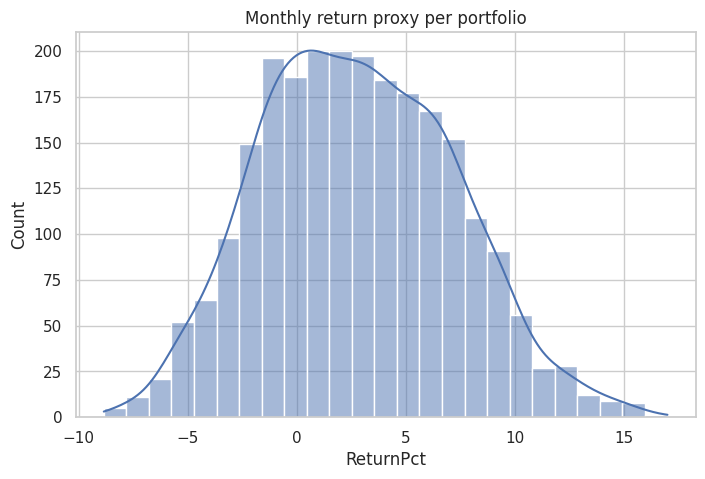

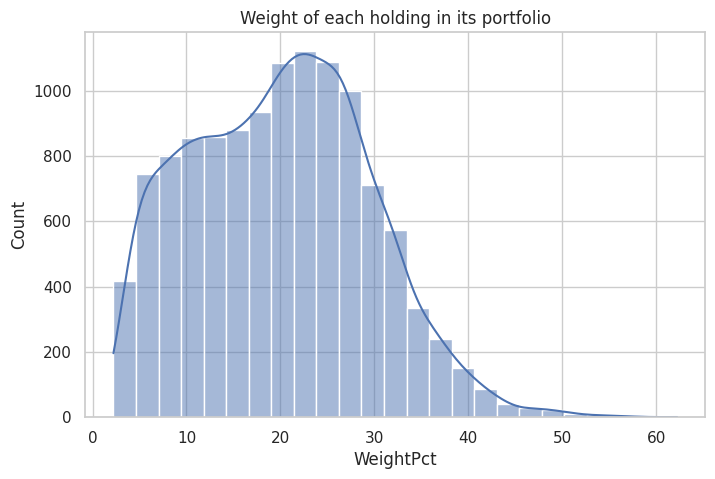

Median monthly return proxy: 2.63 %
Portfolio-months with a negative return proxy: 28.7 %
Holdings above 25% (the highest cap): 31.4 %
Business meaning: with five holdings, concentration is built into the portfolios, so the review should look at caps and holding counts, not only single trades.


In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=pm, x='ReturnPct', bins=25, kde=True)
plt.title('Monthly return proxy per portfolio')
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data=hw, x='WeightPct', bins=25, kde=True)
plt.title('Weight of each holding in its portfolio')
plt.show()

print('Median monthly return proxy:', round(pm['ReturnPct'].median(), 2), '%')
print('Portfolio-months with a negative return proxy:', round((pm['ReturnPct'] < 0).mean() * 100, 1), '%')
print('Holdings above 25% (the highest cap):', round((hw['WeightPct'] > 25).mean() * 100, 1), '%')
print('Business meaning: with five holdings, concentration is built into the portfolios, so the review should look at caps and holding counts, not only single trades.')

###  Trend: AUM and return against benchmark (line plot)

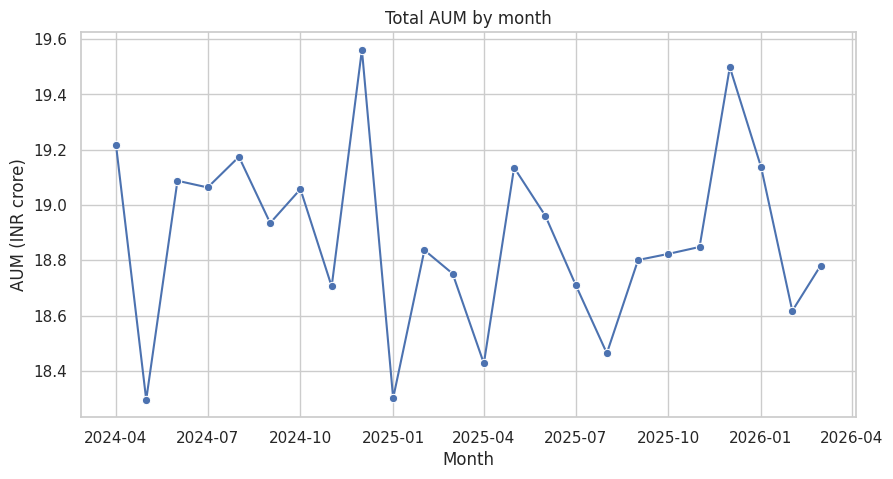

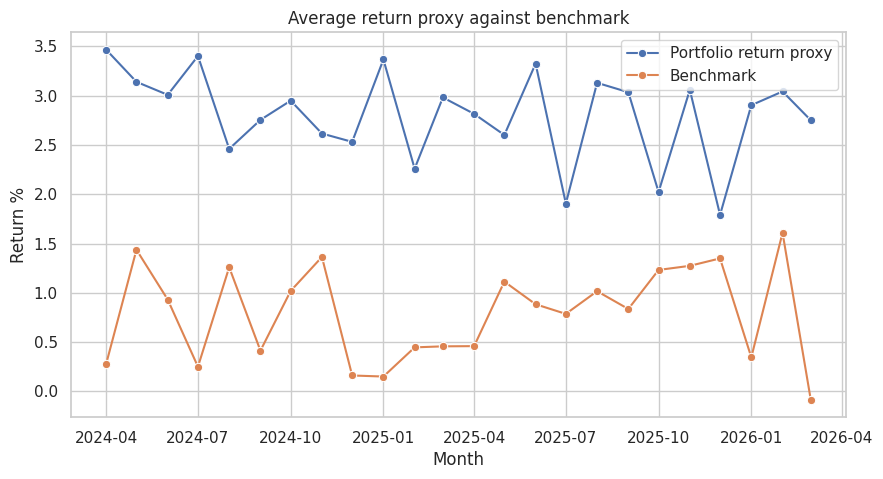

AUM changed by -2.3 % from first to last month.
Return proxy is above the benchmark in 24 of 24 months, by 2.01 points on average.
Caution: the proxy is (market value - cost) / cost. A gap in almost every month points to the measure, not to skill.


In [ ]:
monthly = pm.groupby('Month', as_index=False).agg(
    AUM=('TotalMV', 'sum'), AvgReturn=('ReturnPct', 'mean'), AvgBenchmark=('BenchmarkReturnPct', 'mean'), EquityBreachRate=('EquityBreach', 'mean'))
monthly['AUM_crore'] = monthly['AUM'] / 1e7
monthly['EquityBreachRate'] = monthly['EquityBreachRate'] * 100

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly, x='Month', y='AUM_crore', marker='o')
plt.title('Total AUM by month')
plt.ylabel('AUM (INR crore)')
plt.show()

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly, x='Month', y='AvgReturn', marker='o', label='Portfolio return proxy')
sns.lineplot(data=monthly, x='Month', y='AvgBenchmark', marker='o', label='Benchmark')
plt.title('Average return proxy against benchmark')
plt.ylabel('Return %')
plt.show()

gap = monthly['AvgReturn'] - monthly['AvgBenchmark']
print('AUM changed by', round((monthly['AUM_crore'].iloc[-1] / monthly['AUM_crore'].iloc[0] - 1) * 100, 1), '% from first to last month.')
print('Return proxy is above the benchmark in', (gap > 0).sum(), 'of', len(gap), 'months, by', round(gap.mean(), 2), 'points on average.')
print('Caution: the proxy is (market value - cost) / cost. A gap in almost every month points to the measure, not to skill.')

###  Correlation heatmap and scatter matrix

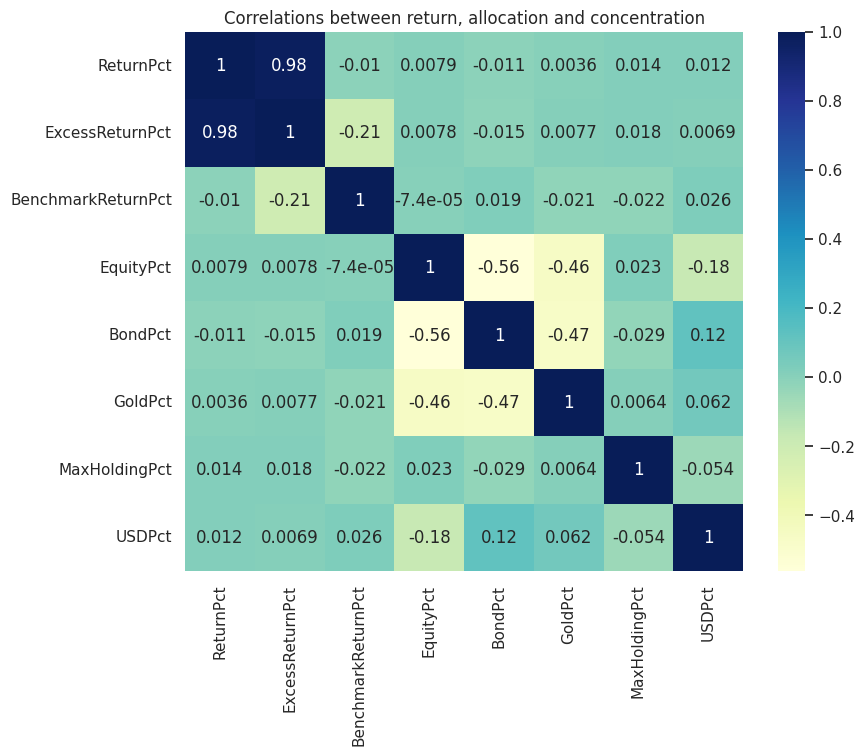

Return and equity share: r = 0.01
Equity and bond share: r = -0.56 (weights add to 100%, so shares move against each other)
Remember: correlation does not prove causation.


In [ ]:
corr_data = pm[['ReturnPct', 'ExcessReturnPct', 'BenchmarkReturnPct', 'EquityPct', 'BondPct', 'GoldPct', 'MaxHoldingPct', 'USDPct']]
correlation = corr_data.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, cmap='YlGnBu')
plt.title('Correlations between return, allocation and concentration')
plt.show()

print('Return and equity share: r =', round(correlation.loc['ReturnPct', 'EquityPct'], 2))
print('Equity and bond share: r =', round(correlation.loc['EquityPct', 'BondPct'], 2), '(weights add to 100%, so shares move against each other)')
print('Remember: correlation does not prove causation.')

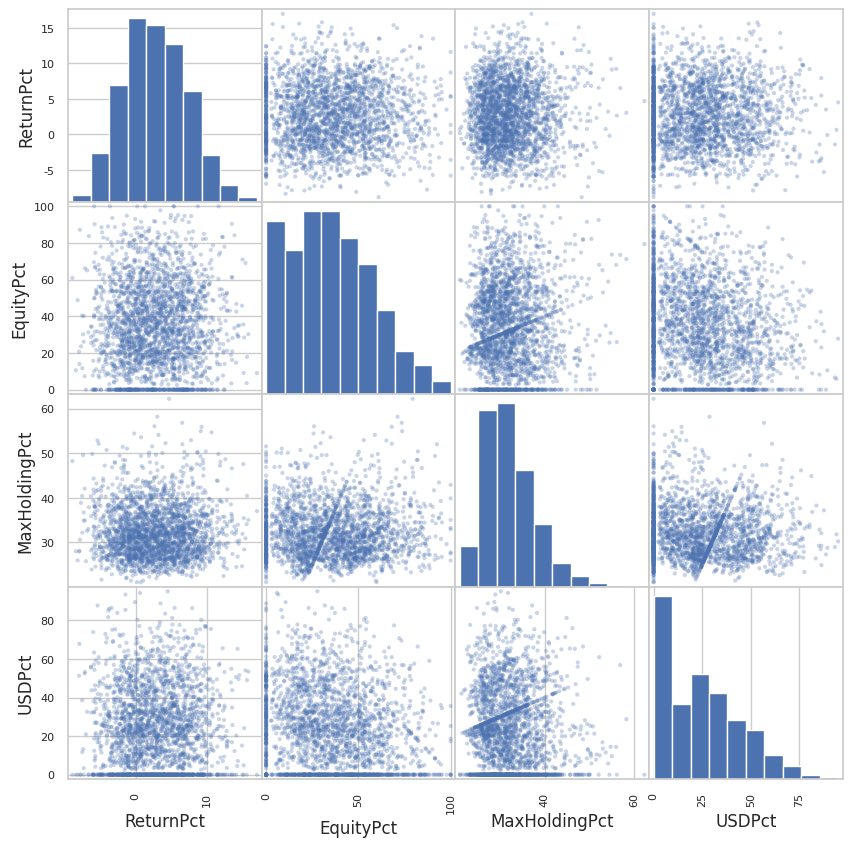

How to read: diagonal = distribution of each measure, other panels = relationship between two measures. Look for straight-line patterns and clusters.
Use focused charts after the matrix; the matrix is for screening.


In [ ]:
scatter_data = pm[['ReturnPct', 'EquityPct', 'MaxHoldingPct', 'USDPct']]
pd.plotting.scatter_matrix(scatter_data, alpha=0.3, figsize=(10, 10), diagonal='hist')
plt.show()
print('How to read: diagonal = distribution of each measure, other panels = relationship between two measures. Look for straight-line patterns and clusters.')
print('Use focused charts after the matrix; the matrix is for screening.')

###  Outliers: identify, investigate, decide
- **Identify:** values outside Q1 - 1.5 x IQR and Q3 + 1.5 x IQR

In [ ]:
outlier_rows = []
for col in ['ReturnPct', 'ExcessReturnPct', 'EquityPct', 'MaxHoldingPct', 'TotalMV']:
    q_low = pm[col].quantile(0.25)
    q_high = pm[col].quantile(0.75)
    iqr = q_high - q_low
    lower = q_low - 1.5 * iqr
    upper = q_high + 1.5 * iqr
    n_low = (pm[col] < lower).sum()
    n_high = (pm[col] > upper).sum()
    outlier_rows.append([col, q_low, q_high, lower, upper, n_low, n_high, (n_low + n_high) / len(pm) * 100, pm[col].min(), pm[col].max()])
outlier_review = pd.DataFrame(outlier_rows, columns=['Measure', 'Q1', 'Q3', 'Lower fence', 'Upper fence', 'Outliers low', 'Outliers high', 'Outlier %', 'Min', 'Max'])
outlier_review

,Measure,Q1,Q3,Lower fence,Upper fence,Outliers low,Outliers high,Outlier %,Min,Max
0,ReturnPct,-0.55,6.00,-10.38,15.83,0,1,0.04,-8.85,17.00
1,ExcessReturnPct,-1.34,5.18,-11.13,14.96,0,3,0.12,-9.82,16.16
2,EquityPct,18.30,51.07,-30.85,100.23,0,0,0.00,0.00,100.00
3,MaxHoldingPct,28.07,35.57,16.83,46.81,0,58,2.42,21.11,62.21
4,TotalMV,"1,597,849.25","2,189,512.75","710,354.00","3,077,008.00",4,0,0.17,"505,635.00","3,076,763.00"


In [ ]:
# Investigate: are the extreme values possible?
valid = pm['EquityPct'].between(0, 100).all() and pm['MaxHoldingPct'].between(0, 100).all() and (pm['TotalMV'] > 0).all()
print('All equity and weight values between 0 and 100, and all values positive:', valid)

# Look at the most extreme return proxies
extreme = pm.reindex(pm['ReturnPct'].abs().sort_values(ascending=False).index).head(5)
extreme[['PortfolioID', 'Month', 'RiskProfile', 'ReturnPct', 'BenchmarkReturnPct', 'EquityPct', 'MaxHoldingPct']]

All equity and weight values between 0 and 100, and all values positive: True


,PortfolioID,Month,RiskProfile,ReturnPct,BenchmarkReturnPct,EquityPct,MaxHoldingPct
239,P010,2026-03-01,Moderate,17.00,0.84,9.03,37.03
1494,P063,2024-10-01,Aggressive,15.81,0.75,30.25,35.07
1146,P048,2025-10-01,Moderate,15.62,1.63,17.93,40.46
1330,P056,2025-02-01,Aggressive,15.57,1.42,3.58,34.10
1808,P076,2024-12-01,Conservative,15.41,0.81,69.10,30.90


###  Boxplots: spread and outliers by risk profile

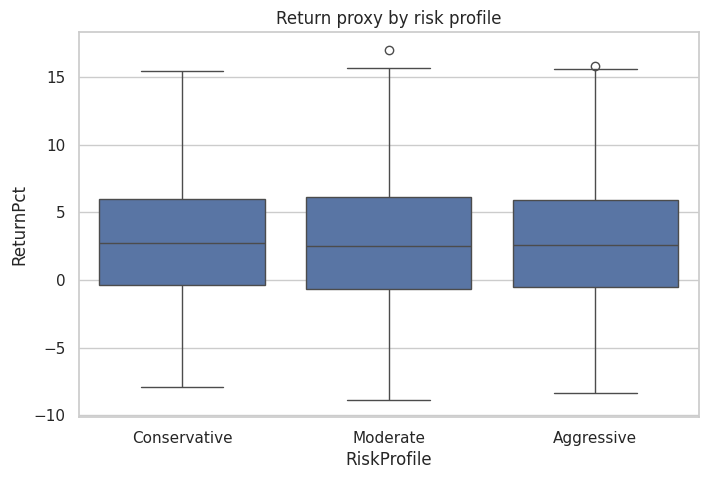

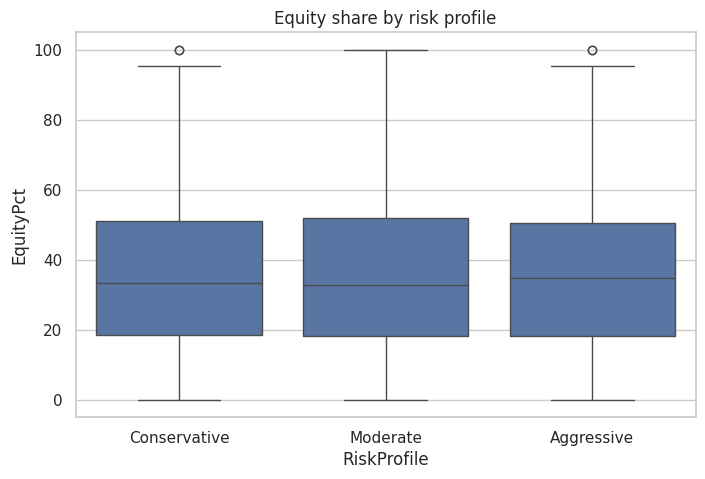

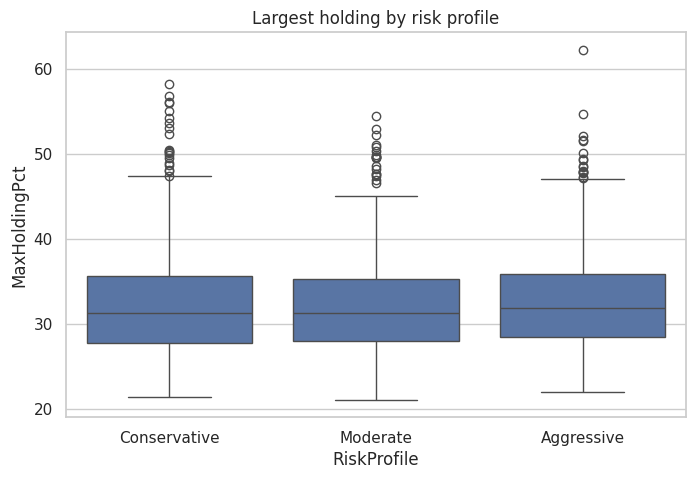

              ReturnPct  EquityPct  MaxHoldingPct
RiskProfile                                      
Conservative       2.74      33.24          31.35
Moderate           2.52      32.92          31.29
Aggressive         2.57      34.84          31.84
Median equity share: Conservative 33 %, Moderate 33 %, Aggressive 35 %.
If the three medians are close, the risk profile is not driving the allocation the way a mandate should. Ask the client about the profile labels and equity limits.


In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=pm, x='RiskProfile', y='ReturnPct', order=order)
plt.title('Return proxy by risk profile')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=pm, x='RiskProfile', y='EquityPct', order=order)
plt.title('Equity share by risk profile')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=pm, x='RiskProfile', y='MaxHoldingPct', order=order)
plt.title('Largest holding by risk profile')
plt.show()

medians = pm.groupby('RiskProfile')[['ReturnPct', 'EquityPct', 'MaxHoldingPct']].median().loc[order]
print(medians)
print('Median equity share: Conservative', round(medians.loc['Conservative', 'EquityPct']), '%, Moderate', round(medians.loc['Moderate', 'EquityPct']), '%, Aggressive', round(medians.loc['Aggressive', 'EquityPct']), '%.')
print('If the three medians are close, the risk profile is not driving the allocation the way a mandate should. Ask the client about the profile labels and equity limits.')

##  Q3 – Are high returns achieved through disproportionate volatility or drawdown?
**Method** (for each portfolio over the 24 months):
- Average return = mean of the monthly return proxy
- Volatility = standard deviation of the monthly return proxy
- Max drawdown = biggest fall from a previous high of the compounded index, where index = running product of (1 + return / 100)
- Return per unit of risk = average return / volatility

A portfolio is **high return, high risk** when both its average return and its volatility are in the top quartile.

**Assumption:** the return proxy is used as a monthly return, as in the SQL view. It is not time-weighted.

In [ ]:
# Max drawdown per portfolio: compounded index, running peak, fall from the peak
def drawdown_by_portfolio(data):
    d = data.sort_values(['PortfolioID', 'Month']).copy()
    d['Index'] = (1 + d['ReturnPct'] / 100).groupby(d['PortfolioID']).cumprod()
    d['Peak'] = d.groupby('PortfolioID')['Index'].cummax()
    d['Drop'] = (d['Peak'] - d['Index']) / d['Peak'] * 100
    return d.groupby('PortfolioID')['Drop'].max()

q3 = pm.groupby(['PortfolioID', 'RiskProfile'], as_index=False).agg(
    AvgReturn=('ReturnPct', 'mean'),
    Volatility=('ReturnPct', 'std'),
    WorstMonth=('ReturnPct', 'min'),
    AvgBenchmark=('BenchmarkReturnPct', 'mean'),
    AvgExcess=('ExcessReturnPct', 'mean'),
    AvgEquity=('EquityPct', 'mean'))
q3['MaxDrawdown'] = q3['PortfolioID'].map(drawdown_by_portfolio(pm))
q3['ReturnPerRisk'] = q3['AvgReturn'] / q3['Volatility']

# Top quartile cut-offs, then labels
return_cut = q3['AvgReturn'].quantile(0.75)
risk_cut = q3['Volatility'].quantile(0.75)
q3['Q3Flag'] = 'Other'
q3.loc[q3['AvgReturn'] >= return_cut, 'Q3Flag'] = 'High return, lower risk'
q3.loc[q3['Volatility'] >= risk_cut, 'Q3Flag'] = 'Lower return, high risk'
q3.loc[(q3['AvgReturn'] >= return_cut) & (q3['Volatility'] >= risk_cut), 'Q3Flag'] = 'High return, high risk'

print(q3['Q3Flag'].value_counts())
high = q3[q3['Q3Flag'] == 'High return, high risk'].sort_values('ReturnPerRisk')
high[['PortfolioID', 'RiskProfile', 'AvgReturn', 'Volatility', 'MaxDrawdown', 'ReturnPerRisk', 'AvgEquity']]

Q3Flag
Other                      57
Lower return, high risk    18
High return, lower risk    18
High return, high risk      7
Name: count, dtype: int64


,PortfolioID,RiskProfile,AvgReturn,Volatility,MaxDrawdown,ReturnPerRisk,AvgEquity
16,P017,Moderate,3.40,5.68,8.92,0.60,40.54
53,P054,Conservative,3.41,5.19,10.15,0.66,42.49
28,P029,Aggressive,3.65,5.45,8.80,0.67,30.83
60,P061,Conservative,3.67,5.47,9.04,0.67,36.72
27,P028,Aggressive,3.56,5.21,5.20,0.68,39.29
75,P076,Conservative,3.65,5.28,5.50,0.69,48.23
94,P095,Conservative,4.12,5.86,14.37,0.70,36.14


In [ ]:
plt.figure(figsize=(8, 5))
sns.regplot(data=q3, x='Volatility', y='AvgReturn')
plt.title('Average return against volatility, one point per portfolio')
plt.xlabel('Volatility of monthly return proxy (%)')
plt.ylabel('Average monthly return proxy (%)')
plt.show()

plt.figure(figsize=(8, 5))
sns.regplot(data=q3, x='MaxDrawdown', y='AvgReturn')
plt.title('Average return against maximum drawdown, one point per portfolio')
plt.xlabel('Maximum drawdown (%)')
plt.ylabel('Average monthly return proxy (%)')
plt.show()

r_vol = q3['AvgReturn'].corr(q3['Volatility'])
r_dd = q3['AvgReturn'].corr(q3['MaxDrawdown'])
print(len(high), 'of', len(q3), 'portfolios are high return, high risk. By profile:')
print(high['RiskProfile'].value_counts())
print('Correlation of average return with volatility:', round(r_vol, 2), ' with max drawdown:', round(r_dd, 2))
if r_vol >= 0.3:
    print('Answer: higher return went with higher volatility, so part of the return looks like risk taking (association, not cause).')
elif r_vol <= -0.3:
    print('Answer: higher return went with lower volatility, so high returns were not bought with extra volatility.')
else:
    print('Answer: the link between return and volatility is weak.')
print('Action: review the high return, high risk group first, starting with the lowest return per unit of risk, and check the risk fits the client profile.')

##  Q6 – Persistent or temporary allocation and tracking variance?
**Allocation variance** = months in breach of the equity limit, out of 24:
- **Persistent**: 12 or more months. **Temporary**: 1 to 11. **None**: 0.

**Tracking variance** = gap to the benchmark.
- The return proxy sits above the benchmark for almost every portfolio, so the raw gap measures the proxy, not performance.
- The fair test is the gap **relative to peers** (excess return minus the average excess in the same month).
- t-statistic = mean gap / (standard deviation / square root of the number of months). A gap is persistent when the absolute t is above 2.
- With 100 portfolios, about 5 would pass this test by chance alone.

In [ ]:
q6 = pm.groupby(['PortfolioID', 'RiskProfile', 'EquityLimitPct'], as_index=False).agg(
    Months=('Month', 'count'),
    EquityBreachMonths=('EquityBreach', 'sum'),
    EffSingleBreachMonths=('EffSingleBreach', 'sum'),
    MeanExcess=('ExcessReturnPct', 'mean'),
    ExcessStd=('ExcessReturnPct', 'std'),
    MeanRelExcess=('RelExcessPct', 'mean'),
    RelExcessStd=('RelExcessPct', 'std'))

q6['RawTStat'] = q6['MeanExcess'] / (q6['ExcessStd'] / np.sqrt(q6['Months']))
q6['TStat'] = q6['MeanRelExcess'] / (q6['RelExcessStd'] / np.sqrt(q6['Months']))

q6['AllocationStatus'] = 'None'
q6.loc[q6['EquityBreachMonths'] >= 1, 'AllocationStatus'] = 'Temporary'
q6.loc[q6['EquityBreachMonths'] >= 12, 'AllocationStatus'] = 'Persistent'

q6['TrackingStatus'] = 'Noise'
q6.loc[q6['TStat'] > 2, 'TrackingStatus'] = 'Persistent positive gap'
q6.loc[q6['TStat'] < -2, 'TrackingStatus'] = 'Persistent negative gap'

print(pd.crosstab(q6['EquityLimitPct'], q6['AllocationStatus'], margins=True))
print()
print(pd.crosstab(q6['RiskProfile'], q6['AllocationStatus'], margins=True))

AllocationStatus  None  Persistent  Temporary  All
EquityLimitPct                                    
35                   0          22         15   37
55                   1           0         36   37
75                   6           0         20   26
All                  7          22         71  100

AllocationStatus  None  Persistent  Temporary  All
RiskProfile                                       
Aggressive           2           6         19   27
Conservative         0          10         27   37
Moderate             5           6         25   36
All                  7          22         71  100


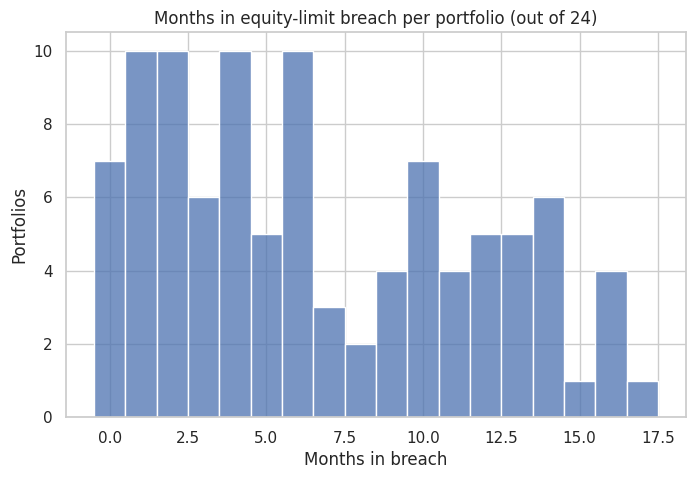

Persistent: 22  Temporary: 71  None: 7
Persistent portfolios by equity limit:
EquityLimitPct
35    22
Name: count, dtype: int64
Action: persistent breaches need a policy or limit decision. Temporary breaches can be cleared by normal rebalancing.


In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=q6, x='EquityBreachMonths', discrete=True)
plt.title('Months in equity-limit breach per portfolio (out of 24)')
plt.xlabel('Months in breach')
plt.ylabel('Portfolios')
plt.show()

n_persistent = (q6['AllocationStatus'] == 'Persistent').sum()
n_temporary = (q6['AllocationStatus'] == 'Temporary').sum()
n_none = (q6['AllocationStatus'] == 'None').sum()
print('Persistent:', n_persistent, ' Temporary:', n_temporary, ' None:', n_none)
print('Persistent portfolios by equity limit:')
print(q6[q6['AllocationStatus'] == 'Persistent']['EquityLimitPct'].value_counts())
print('Action: persistent breaches need a policy or limit decision. Temporary breaches can be cleared by normal rebalancing.')

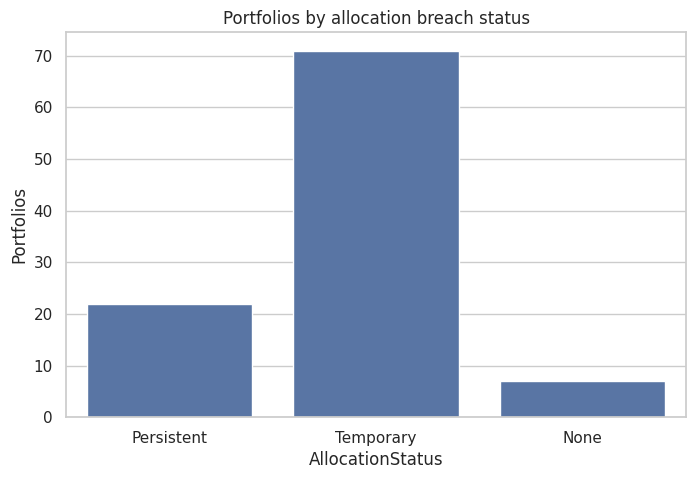

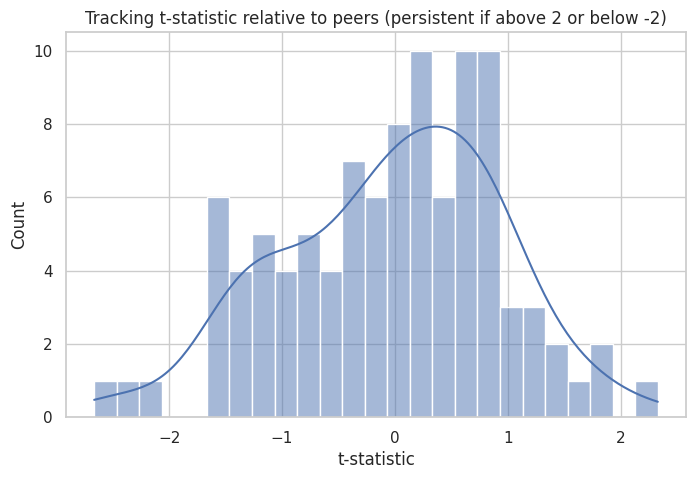

Against the raw benchmark, 59 of 100 portfolios have |t| above 2 (the proxy sits above the benchmark for almost everyone).
Relative to peers, 4 of 100 have |t| above 2. About 5 are expected by chance.
Peer-relative tracking gaps are close to chance, so they look like noise.


In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=q6, x='AllocationStatus', order=['Persistent', 'Temporary', 'None'])
plt.title('Portfolios by allocation breach status')
plt.ylabel('Portfolios')
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data=q6, x='TStat', bins=25, kde=True)
plt.title('Tracking t-statistic relative to peers (persistent if above 2 or below -2)')
plt.xlabel('t-statistic')
plt.show()

n_raw = (q6['RawTStat'].abs() > 2).sum()
n_rel = (q6['TStat'].abs() > 2).sum()
print('Against the raw benchmark,', n_raw, 'of', len(q6), 'portfolios have |t| above 2 (the proxy sits above the benchmark for almost everyone).')
print('Relative to peers,', n_rel, 'of', len(q6), 'have |t| above 2. About', round(0.05 * len(q6)), 'are expected by chance.')
if n_rel <= 2 * 0.05 * len(q6):
    print('Peer-relative tracking gaps are close to chance, so they look like noise.')
else:
    print('More portfolios than chance would give track differently from peers.')

## 8. Q8 – How would market, rate, currency and commodity scenarios affect portfolios?
Scenarios are **what-if tests on the latest month's holdings**, not forecasts. The data has no prices, durations or FX rates, so each shock is an **assumption you can edit** in the first cell.

| Scenario | Shock applied to latest-month market value |
|---|---|
| Equity -15% | every Equity holding falls 15% |
| Rates +100bp | every Bond holding falls 5% (assumes a duration of about 5 years) |
| INR +5% | every USD holding loses 5% in INR terms (rupee strengthens) |
| Gold -10% | every Gold holding falls 10% |
| Combined stress | all four together |

In [ ]:
# Shocks (edit here)
EQUITY_SHOCK = -0.15
BOND_SHOCK = -0.05
GOLD_SHOCK = -0.10
USD_SHOCK = -0.05

latest_hw = hw[hw['Month'] == latest_month].copy()

# Factor for each holding: 1 means no change
latest_hw['EquityFactor'] = 1.0
latest_hw.loc[latest_hw['AssetClass'] == 'Equity', 'EquityFactor'] = 1 + EQUITY_SHOCK
latest_hw['BondFactor'] = 1.0
latest_hw.loc[latest_hw['AssetClass'] == 'Bond', 'BondFactor'] = 1 + BOND_SHOCK
latest_hw['GoldFactor'] = 1.0
latest_hw.loc[latest_hw['AssetClass'] == 'Gold', 'GoldFactor'] = 1 + GOLD_SHOCK
latest_hw['USDFactor'] = 1.0
latest_hw.loc[latest_hw['Currency'] == 'USD', 'USDFactor'] = 1 + USD_SHOCK

# Value of each holding under each scenario
latest_hw['Equity -15%'] = latest_hw['MarketValueINR'] * latest_hw['EquityFactor']
latest_hw['Rates +100bp'] = latest_hw['MarketValueINR'] * latest_hw['BondFactor']
latest_hw['INR +5%'] = latest_hw['MarketValueINR'] * latest_hw['USDFactor']
latest_hw['Gold -10%'] = latest_hw['MarketValueINR'] * latest_hw['GoldFactor']
latest_hw['Combined stress'] = latest_hw['MarketValueINR'] * latest_hw['EquityFactor'] * latest_hw['BondFactor'] * latest_hw['GoldFactor'] * latest_hw['USDFactor']

scenario_names = ['Equity -15%', 'Rates +100bp', 'INR +5%', 'Gold -10%', 'Combined stress']

# Add up by portfolio (the holdings table has one row per holding, so we sum, we never join)
scen = latest_hw.groupby(['PortfolioID', 'RiskProfile', 'EquityLimitPct'], as_index=False)[['MarketValueINR'] + scenario_names].sum()
for name in scenario_names:
    scen[name + ' %'] = (scen[name] / scen['MarketValueINR'] - 1) * 100
print('Portfolios in scenario table:', len(scen))

# Summary of each scenario
summary_rows = []
for name in scenario_names:
    change = scen[name].sum() - scen['MarketValueINR'].sum()
    summary_rows.append([name, scen[name + ' %'].mean(), scen[name + ' %'].min(), scen[name + ' %'].max(), change / 1e7, change / scen['MarketValueINR'].sum() * 100])
scenario_summary = pd.DataFrame(summary_rows, columns=['Scenario', 'Average impact %', 'Worst portfolio %', 'Best portfolio %', 'Total change (INR crore)', 'Total change %'])
scenario_summary

Portfolios in scenario table: 100


,Scenario,Average impact %,Worst portfolio %,Best portfolio %,Total change (INR crore),Total change %
0,Equity -15%,-4.81,-15.00,0.00,-0.89,-4.76
1,Rates +100bp,-1.90,-5.00,0.00,-0.35,-1.87
2,INR +5%,-1.18,-3.82,0.00,-0.23,-1.20
3,Gold -10%,-2.99,-10.00,0.00,-0.58,-3.08
4,Combined stress,-10.78,-15.69,-5.71,-2.03,-10.81


In [ ]:
pct_cols = [name + ' %' for name in scenario_names]
by_profile_scen = scen.groupby('RiskProfile')[pct_cols].mean().loc[order]
by_profile_scen

,Equity -15% %,Rates +100bp %,INR +5% %,Gold -10% %,Combined stress %
RiskProfile,,,,,
Conservative,-5.32,-1.77,-1.34,-2.91,-11.21
Moderate,-4.59,-2.06,-1.15,-2.82,-10.54
Aggressive,-4.40,-1.88,-1.01,-3.31,-10.51


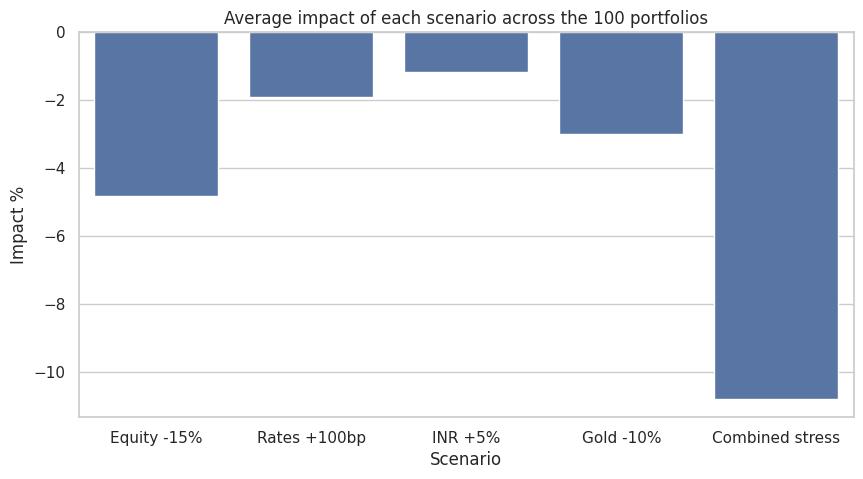

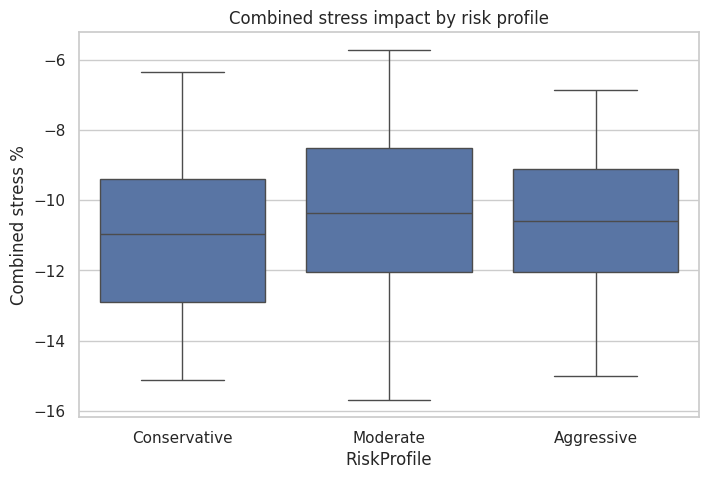

Combined stress changes total AUM by -10.8 % (INR -2.03 crore).
Average combined impact by profile:
RiskProfile
Conservative   -11.20
Moderate       -10.50
Aggressive     -10.50
Name: Combined stress %, dtype: float64
Gap between the best and worst profile: 0.7 points.
The profiles lose almost the same amount, so the risk profile is not limiting downside the way a mandate should.
Five portfolios with the largest combined loss:


,PortfolioID,RiskProfile,EquityLimitPct,Combined stress %
47,P048,Moderate,35,-15.69
23,P024,Conservative,35,-15.12
38,P039,Aggressive,55,-15.00
42,P043,Aggressive,35,-14.96
59,P060,Conservative,55,-14.93


In [ ]:
long = scen.melt(id_vars=['PortfolioID', 'RiskProfile'], value_vars=pct_cols, var_name='Scenario', value_name='Impact %')
long['Scenario'] = long['Scenario'].str.replace(' %', '', regex=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=long, x='Scenario', y='Impact %', order=scenario_names, errorbar=None)
plt.title('Average impact of each scenario across the 100 portfolios')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=scen, x='RiskProfile', y='Combined stress %', order=order)
plt.title('Combined stress impact by risk profile')
plt.show()

combined = scenario_summary[scenario_summary['Scenario'] == 'Combined stress'].iloc[0]
profile_gap = by_profile_scen['Combined stress %'].max() - by_profile_scen['Combined stress %'].min()
print('Combined stress changes total AUM by', round(combined['Total change %'], 1), '% (INR', round(combined['Total change (INR crore)'], 2), 'crore).')
print('Average combined impact by profile:')
print(by_profile_scen['Combined stress %'].round(1))
print('Gap between the best and worst profile:', round(profile_gap, 1), 'points.')
if profile_gap < 2:
    print('The profiles lose almost the same amount, so the risk profile is not limiting downside the way a mandate should.')
else:
    print('The profiles lose clearly different amounts, so the profile does limit downside.')
print('Five portfolios with the largest combined loss:')
scen.nsmallest(5, 'Combined stress %')[['PortfolioID', 'RiskProfile', 'EquityLimitPct', 'Combined stress %']]

In [ ]:
# Sensitivity: how does the equity shock change the answer?
equity_mv = latest_hw[latest_hw['AssetClass'] == 'Equity']['MarketValueINR'].sum()
total_mv = latest_hw['MarketValueINR'].sum()
sens_rows = []
for shock in [-0.05, -0.10, -0.15, -0.20, -0.30]:
    change = equity_mv * shock
    sens_rows.append([shock * 100, change / total_mv * 100, change / 1e7])
sensitivity = pd.DataFrame(sens_rows, columns=['Equity shock %', 'AUM change %', 'AUM change (INR crore)'])
sensitivity

,Equity shock %,AUM change %,AUM change (INR crore)
0,-5.00,-1.59,-0.30
1,-10.00,-3.17,-0.60
2,-15.00,-4.76,-0.89
3,-20.00,-6.34,-1.19
4,-30.00,-9.52,-1.79


##  Rolling forecast against naive and seasonal-naive baselines
The brief asks for at least one rolling forecast compared with a baseline, with stability, release lags, revisions, scenarios and error by horizon.

**Two monthly series (24 points):** total AUM (INR crore) and the share of portfolios in equity-limit breach (%).

**Methods, all using only past data:**
- **Naive:** repeat the last known value (`shift`)
- **Seasonal naive:** use the value from 12 months earlier (`shift(12)`)
- **Rolling 3-month average:** average of the last 3 known months (`rolling(3).mean()`)

**Horizons:** 1, 2 and 3 months ahead. For a forecast `h` months ahead, the last known month is `h` months before the target, so everything is shifted by `h`.
**Error:** mean absolute error (MAE) on the same months for every method (12 test months). **Skill** = 1 - MAE of the rolling average / MAE of naive. A positive skill means the rolling average beats naive.

**Release lag and revisions.** The data are month-end positions. In practice they arrive after month close, so a real forecast made in month `t` would only know data up to `t-1`, which makes each horizon one month longer. This synthetic data has no restatements, so revision risk cannot be measured here; real valuation data are often revised.

In [ ]:
series = {
    'Total AUM (INR crore)': monthly['AUM_crore'],
    'Equity breach rate (%)': monthly['EquityBreachRate']}
methods = ['Naive', 'Seasonal naive', 'Rolling 3-month average']

error_rows = []
one_month = {}
for name in series:
    y = series[name]
    for h in [1, 2, 3]:
        fc = pd.DataFrame({'Actual': y})
        fc['Naive'] = y.shift(h)
        fc['Seasonal naive'] = y.shift(12)
        fc['Rolling 3-month average'] = y.rolling(3).mean().shift(h)
        fc = fc.dropna()                          # keep only months where every method has a forecast
        row = [name, h, len(fc)]
        for method in methods:
            row.append((fc['Actual'] - fc[method]).abs().mean())
        error_rows.append(row)
        if h == 1:
            fc['Month'] = monthly['Month']
            one_month[name] = fc

forecast_error = pd.DataFrame(error_rows, columns=['Series', 'Horizon (months)', 'Forecasts', 'MAE Naive', 'MAE Seasonal naive', 'MAE Rolling 3-month average'])
forecast_error['Skill vs naive'] = 1 - forecast_error['MAE Rolling 3-month average'] / forecast_error['MAE Naive']
forecast_error['Skill vs seasonal'] = 1 - forecast_error['MAE Rolling 3-month average'] / forecast_error['MAE Seasonal naive']
forecast_error

,Series,Horizon (months),Forecasts,MAE Naive,MAE Seasonal naive,MAE Rolling 3-month average,Skill vs naive,Skill vs seasonal
0,Total AUM (INR crore),1,12,0.32,0.37,0.29,0.08,0.23
1,Total AUM (INR crore),2,12,0.41,0.37,0.34,0.18,0.09
2,Total AUM (INR crore),3,12,0.35,0.37,0.28,0.19,0.24
3,Equity breach rate (%),1,12,2.33,5.08,2.39,-0.02,0.53
4,Equity breach rate (%),2,12,3.58,5.08,2.28,0.36,0.55
5,Equity breach rate (%),3,12,2.75,5.08,2.69,0.02,0.47


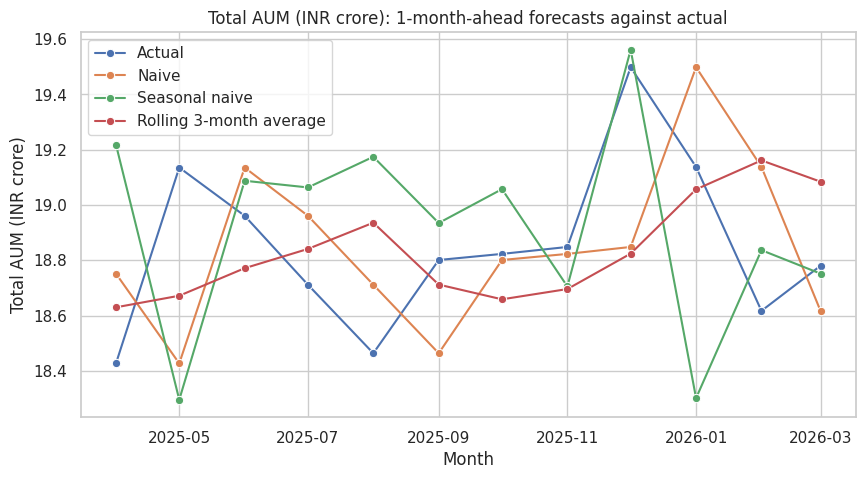

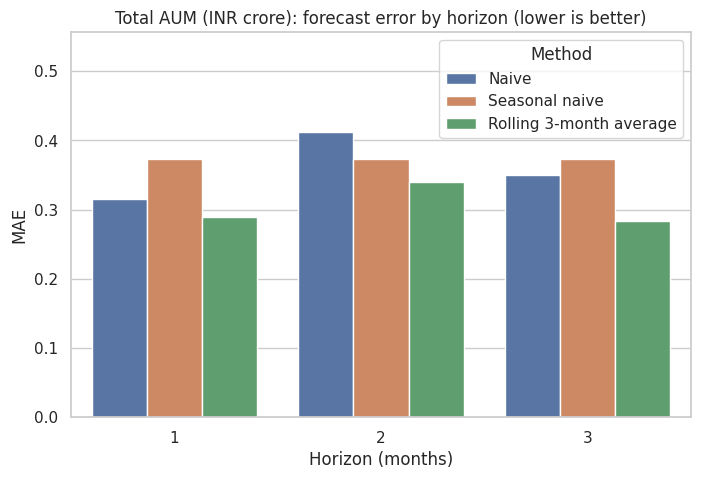

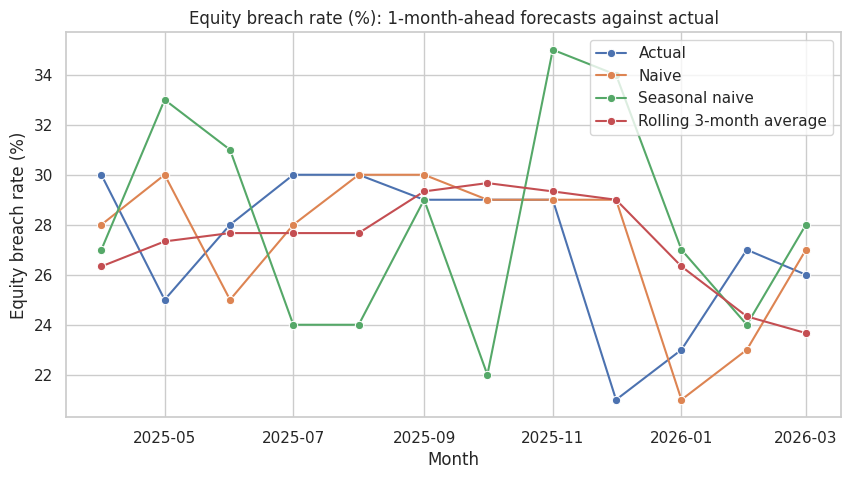

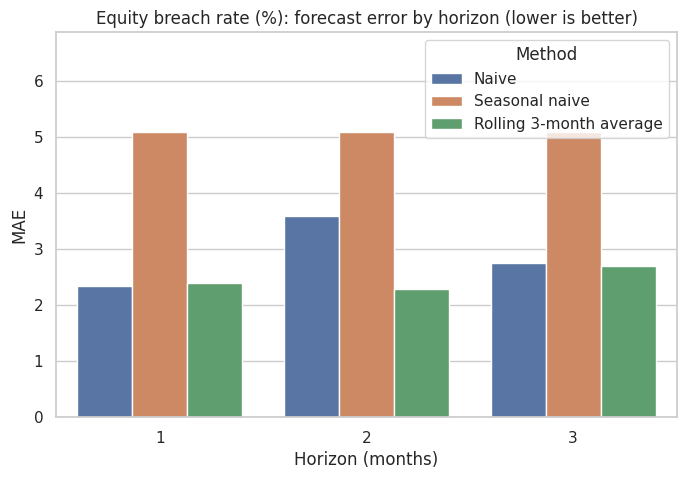

Total AUM (INR crore) - skill of the rolling average against naive: {1: 8.0, 2: 18.0, 3: 19.0} (% by horizon in months)
Equity breach rate (%) - skill of the rolling average against naive: {1: -2.0, 2: 36.0, 3: 2.0} (% by horizon in months)
A positive skill means the rolling average beats naive. If skill is near zero or negative, the series is too noisy and the naive forecast is the honest one.


In [ ]:
for name in series:
    fc = one_month[name]
    plt.figure(figsize=(10, 5))
    for col in ['Actual', 'Naive', 'Seasonal naive', 'Rolling 3-month average']:
        sns.lineplot(data=fc, x='Month', y=col, marker='o', label=col)
    plt.title(name + ': 1-month-ahead forecasts against actual')
    plt.ylabel(name)
    plt.show()

    err = forecast_error[forecast_error['Series'] == name]
    err_long = err.melt(id_vars='Horizon (months)', value_vars=['MAE ' + m for m in methods], var_name='Method', value_name='MAE')
    err_long['Method'] = err_long['Method'].str.replace('MAE ', '', regex=False)
    plt.figure(figsize=(8, 5))
    sns.barplot(data=err_long, x='Horizon (months)', y='MAE', hue='Method')
    plt.ylim(0, err_long['MAE'].max() * 1.35)          # leave room for the legend
    plt.title(name + ': forecast error by horizon (lower is better)')
    plt.show()

for name in series:
    err = forecast_error[forecast_error['Series'] == name].set_index('Horizon (months)')
    print(name, '- skill of the rolling average against naive:', (err['Skill vs naive'] * 100).round(0).to_dict(), '(% by horizon in months)')
print('A positive skill means the rolling average beats naive. If skill is near zero or negative, the series is too noisy and the naive forecast is the honest one.')

### Stability and sensitivity of the forecast

In [ ]:
def mae(fc, column):
    return (fc['Actual'] - fc[column]).abs().mean()

test_rows = []
for name in series:
    y = series[name]
    for window in [3, 6]:                         # sensitivity to the window length
        fc = pd.DataFrame({'Actual': y, 'Naive': y.shift(1), 'Model': y.rolling(window).mean().shift(1)}).dropna()
        half = len(fc) // 2
        first = fc.iloc[:half]                    # stability: first half of the test months
        second = fc.iloc[half:]                   # stability: second half
        test_rows.append([name, 'Window ' + str(window) + ', first half', mae(first, 'Model'), mae(first, 'Naive')])
        test_rows.append([name, 'Window ' + str(window) + ', second half', mae(second, 'Model'), mae(second, 'Naive')])

stability = pd.DataFrame(test_rows, columns=['Series', 'Test', 'MAE rolling average', 'MAE naive'])
stability['Beats naive'] = np.where(stability['MAE rolling average'] < stability['MAE naive'], 'Yes', 'No')
print(stability)
print()
for name in series:
    part = stability[stability['Series'] == name]
    wins = (part['Beats naive'] == 'Yes').sum()
    print(name, ': beats naive in', wins, 'of', len(part), 'tests.')
print('If the answer changes between halves or window lengths, the result is not stable and the forecast should only be used as a range.')
print('Use the scenario table in section 8 for stress cases.')

                   Series                   Test  MAE rolling average  \
0   Total AUM (INR crore)   Window 3, first half                 0.29   
1   Total AUM (INR crore)  Window 3, second half                 0.30   
2   Total AUM (INR crore)   Window 6, first half                 0.32   
3   Total AUM (INR crore)  Window 6, second half                 0.22   
4  Equity breach rate (%)   Window 3, first half                 4.87   
5  Equity breach rate (%)  Window 3, second half                 2.27   
6  Equity breach rate (%)   Window 6, first half                 3.63   
7  Equity breach rate (%)  Window 6, second half                 2.28   

   MAE naive Beats naive  
0       0.39         Yes  
1       0.31         Yes  
2       0.49         Yes  
3       0.29         Yes  
4       4.90         Yes  
5       2.36         Yes  
6       5.00         Yes  
7       2.00          No  

Total AUM (INR crore) : beats naive in 4 of 4 tests.
Equity breach rate (%) : beats naive in 3 of 

##  Q9 – Rule-based risk score tested on later dates
An **explainable 0-100 score**. Each component is scaled from 0 to 1 and multiplied by a fixed weight. The weights are **judgement-based assumptions**, written down before testing and not tuned.

| Component | Weight | Measure (data up to the scoring month only) |
|---|---|---|
| Persistence | 30 | share of the last 6 months in equity breach |
| Equity excess | 25 | equity above the limit now, divided by the largest excess among portfolios |
| Concentration | 15 | largest holding above the feasible cap now, divided by the largest excess |
| Volatility | 15 | standard deviation of the last 6 returns, rank among portfolios (0 to 1) |
| Drawdown | 10 | max drawdown over the last 6 months, rank among portfolios |
| Currency | 5 | USD share now, rank among portfolios |

**Test on later dates only.** At each scoring month, the score uses the 6 months up to that month. The outcome is measured in the **next 6 months**, which the score never saw.
- **Outcome A:** equity breach in 3 or more of the next 6 months
- **Outcome B:** drawdown in the worst quarter of portfolios over the next 6 months
- **Lift** = outcome rate among the top-quarter scores / outcome rate for all portfolios
- The naive rule for comparison: "flag portfolios already in breach today"

In [ ]:
def risk_score(window):
    last = window[window['Month'] == window['Month'].max()].set_index('PortfolioID')
    by_portfolio = window.groupby('PortfolioID')
    comp = pd.DataFrame(index=last.index)
    comp['Persistence'] = by_portfolio['EquityBreach'].mean()
    comp['EquityExcess'] = last['EquityExcessPct'] / last['EquityExcessPct'].max()
    comp['Concentration'] = last['ConcExcessPct'] / last['ConcExcessPct'].max()
    comp['Volatility'] = by_portfolio['ReturnPct'].std().rank(pct=True)
    comp['Drawdown'] = drawdown_by_portfolio(window).rank(pct=True)
    comp['Currency'] = last['USDPct'].rank(pct=True)
    comp['RiskScore'] = 100 * (0.30 * comp['Persistence'] + 0.25 * comp['EquityExcess'] + 0.15 * comp['Concentration']
                               + 0.15 * comp['Volatility'] + 0.10 * comp['Drawdown'] + 0.05 * comp['Currency'])
    return comp

# Score at each possible month, then look at the next 6 months
tests = []
for end in range(5, len(months) - 6):
    window = pm[pm['Month'].isin(months[end - 5: end + 1])]       # 6 months up to the scoring month
    future = pm[pm['Month'].isin(months[end + 1: end + 7])]       # the next 6 months
    result = risk_score(window)[['RiskScore']].copy()
    result['InBreachNow'] = window[window['Month'] == months[end]].set_index('PortfolioID')['EquityBreach']
    result['FutureBreachMonths'] = future.groupby('PortfolioID')['EquityBreach'].sum()
    result['FutureDrawdown'] = drawdown_by_portfolio(future)
    result['OriginNo'] = end
    tests.append(result)
backtest_data = pd.concat(tests)

backtest_data['A'] = (backtest_data['FutureBreachMonths'] >= 3).astype(int)
backtest_data['B'] = (backtest_data['FutureDrawdown'].groupby(backtest_data['OriginNo']).rank(pct=True) > 0.75).astype(int)
backtest_data['TopScore'] = (backtest_data['RiskScore'].groupby(backtest_data['OriginNo']).rank(pct=True) > 0.75).astype(int)
print('Scoring months tested:', backtest_data['OriginNo'].nunique(), ' observations:', len(backtest_data))

Scoring months tested: 13  observations: 1300


In [ ]:
def lift(df, flag, target):
    return df[df[flag] == 1][target].mean() / df[target].mean()

groups = {'All scoring months': backtest_data,
          'Earlier half': backtest_data[backtest_data['OriginNo'] <= 11],
          'Later half': backtest_data[backtest_data['OriginNo'] > 11]}
bt_rows = []
for label in groups:
    df = groups[label]
    bt_rows.append([label, len(df), df['A'].mean() * 100, df[df['TopScore'] == 1]['A'].mean() * 100, lift(df, 'TopScore', 'A'),
                    lift(df, 'InBreachNow', 'A'), df['B'].mean() * 100, df[df['TopScore'] == 1]['B'].mean() * 100, lift(df, 'TopScore', 'B')])
backtest = pd.DataFrame(bt_rows, columns=['Group', 'Observations', 'Base rate A %', 'Top-score rate A %', 'Lift A (score)',
                                          'Lift A (naive: in breach now)', 'Base rate B %', 'Top-score rate B %', 'Lift B (score)'])
backtest

,Group,Observations,Base rate A %,Top-score rate A %,Lift A (score),Lift A (naive: in breach now),Base rate B %,Top-score rate B %,Lift B (score)
0,All scoring months,1300,29.92,58.15,1.94,1.69,25.00,30.46,1.22
1,Earlier half,700,29.86,57.71,1.93,1.68,25.00,25.71,1.03
2,Later half,600,30.00,58.67,1.96,1.71,25.00,36.00,1.44


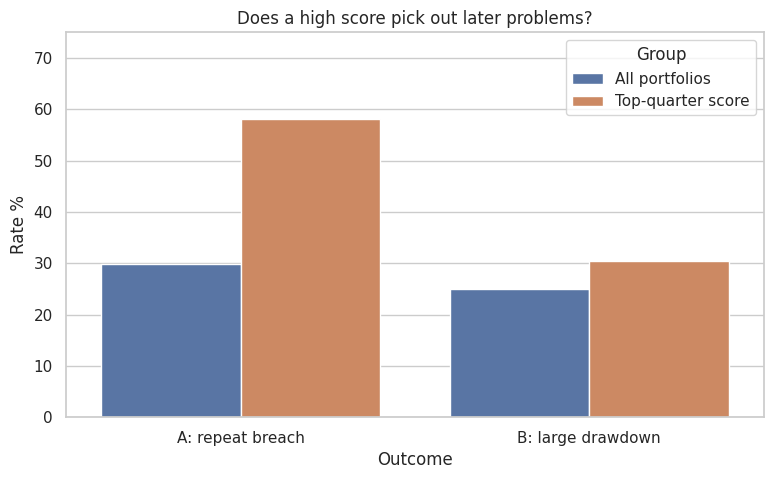

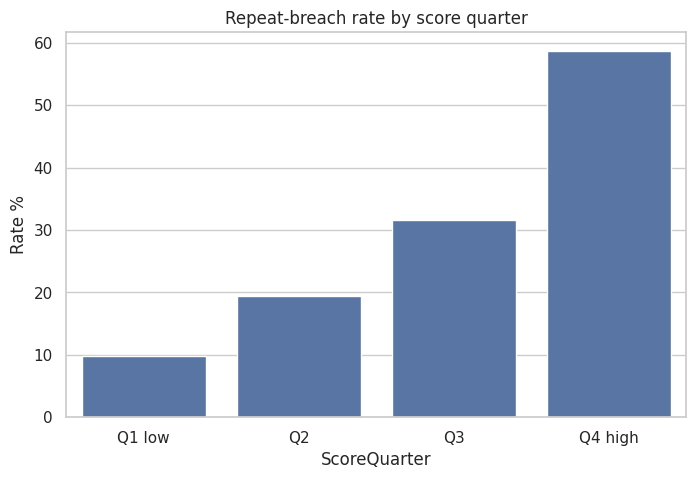

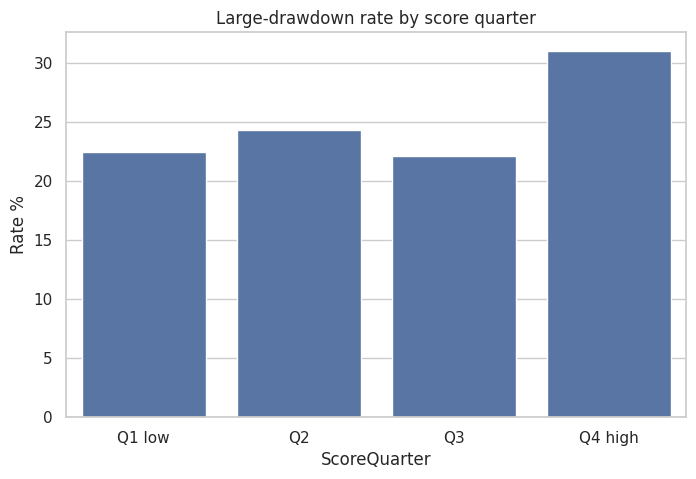

Repeat breach: base rate 29.9 %, top-quarter score 58.2 %.
Lift for the score: 1.94  lift for the naive rule: 1.69
The score beats the naive rule on repeat breaches.
Lift on later drawdown: 1.22 (earlier half 1.03 , later half 1.44 )
The score has only weak power on later drawdown. Do not rely on it for drawdown.
Limits: windows overlap, there are only 100 portfolios, and the weights are judgement-based. Treat the lift as indicative, not proof.


In [ ]:
rates = pd.DataFrame({'Outcome': ['A: repeat breach', 'A: repeat breach', 'B: large drawdown', 'B: large drawdown'],
                      'Group': ['All portfolios', 'Top-quarter score', 'All portfolios', 'Top-quarter score'],
                      'Rate %': [backtest_data['A'].mean() * 100, backtest_data[backtest_data['TopScore'] == 1]['A'].mean() * 100,
                                 backtest_data['B'].mean() * 100, backtest_data[backtest_data['TopScore'] == 1]['B'].mean() * 100]})
plt.figure(figsize=(9, 5))
sns.barplot(data=rates, x='Outcome', y='Rate %', hue='Group')
plt.ylim(0, 75)
plt.title('Does a high score pick out later problems?')
plt.show()

backtest_data['ScoreQuarter'] = pd.qcut(backtest_data['RiskScore'], 4, labels=['Q1 low', 'Q2', 'Q3', 'Q4 high'])
quarter_rates = backtest_data.groupby('ScoreQuarter', observed=True)[['A', 'B']].mean().reset_index()
quarter_rates['A'] = quarter_rates['A'] * 100
quarter_rates['B'] = quarter_rates['B'] * 100

plt.figure(figsize=(8, 5))
sns.barplot(data=quarter_rates, x='ScoreQuarter', y='A')
plt.title('Repeat-breach rate by score quarter')
plt.ylabel('Rate %')
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=quarter_rates, x='ScoreQuarter', y='B')
plt.title('Large-drawdown rate by score quarter')
plt.ylabel('Rate %')
plt.show()

all_rows = backtest.iloc[0]
print('Repeat breach: base rate', round(all_rows['Base rate A %'], 1), '%, top-quarter score', round(all_rows['Top-score rate A %'], 1), '%.')
print('Lift for the score:', round(all_rows['Lift A (score)'], 2), ' lift for the naive rule:', round(all_rows['Lift A (naive: in breach now)'], 2))
if all_rows['Lift A (score)'] > all_rows['Lift A (naive: in breach now)']:
    print('The score beats the naive rule on repeat breaches.')
else:
    print('The score does not beat the naive rule on repeat breaches.')
lift_b = all_rows['Lift B (score)']
print('Lift on later drawdown:', round(lift_b, 2), '(earlier half', round(backtest.iloc[1]['Lift B (score)'], 2), ', later half', round(backtest.iloc[2]['Lift B (score)'], 2), ')')
if lift_b >= 1.5:
    print('The score has useful power on later drawdown.')
elif lift_b >= 1.2:
    print('The score has only weak power on later drawdown. Do not rely on it for drawdown.')
else:
    print('The score has no real power on later drawdown.')
print('Limits: windows overlap, there are only 100 portfolios, and the weights are judgement-based. Treat the lift as indicative, not proof.')

In [ ]:
# Score for every portfolio in the latest month (last 6 months of data)
final = risk_score(pm[pm['Month'].isin(months[-6:])]).reset_index()
final['Band'] = 'Low'
final.loc[final['RiskScore'] >= 40, 'Band'] = 'Medium'
final.loc[final['RiskScore'] >= 60, 'Band'] = 'High'
final = final.merge(pm[pm['Month'] == latest_month][['PortfolioID', 'RiskProfile', 'EquityLimitPct']], on='PortfolioID')
final = final.sort_values('RiskScore', ascending=False).reset_index(drop=True)

print('Score bands:', final['Band'].value_counts().to_dict())
print(pd.crosstab(final['RiskProfile'], final['Band']))
final.head(5)

Score bands: {'Low': 78, 'Medium': 16, 'High': 6}
Band          High  Low  Medium
RiskProfile                    
Aggressive       1   22       4
Conservative     4   26       7
Moderate         1   30       5


,PortfolioID,Persistence,EquityExcess,Concentration,Volatility,Drawdown,Currency,RiskScore,Band,RiskProfile,EquityLimitPct
0,P024,0.50,0.88,0.21,0.93,0.90,0.72,66.83,High,Conservative,35
1,P054,0.67,0.73,0.16,1.00,0.97,0.12,65.86,High,Conservative,35
2,P027,0.83,0.62,0.81,0.25,0.44,0.85,65.18,High,Conservative,35
3,P048,0.50,0.69,0.27,0.97,0.89,0.86,64.06,High,Moderate,35
4,P068,0.50,0.61,0.38,0.96,0.84,0.97,63.59,High,Conservative,35


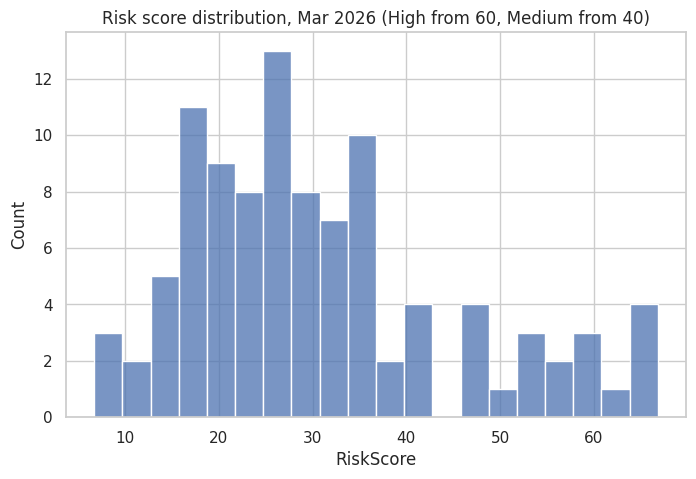

Explainability: each score is a weighted sum of six visible components, so a reviewer can see what drives any portfolio score and challenge it.


In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=final, x='RiskScore', bins=20)
plt.title('Risk score distribution, ' + latest_month.strftime('%b %Y') + ' (High from 60, Medium from 40)')
plt.show()
print('Explainability: each score is a weighted sum of six visible components, so a reviewer can see what drives any portfolio score and challenge it.')

## Q10 – Rebalancing priority list
Built from the latest month, the breach history (Q6), the risk score (Q9) and the Q3 flag.

**Priority rules (fixed in advance):**
- **P1 - Review now:** in equity breach now **and** persistent breach **and** score band High
- **P2 - Review this quarter:** in a breach now (equity limit, or material concentration) **and** (persistent breach **or** score band Medium or High), and not P1
- **P3 - Watchlist:** in a breach now, not P1 or P2
- **P4 - Monitor:** no breach now

Material concentration = 10 or more points above the feasible cap. With 5 holdings almost every portfolio is above its stated cap, so using every small excess would put nearly everyone on the watchlist.

**Amounts (INR):**
- Equity to reduce = equity above the limit as a share of total value
- Concentration to trim = value above the feasible cap, summed over the holdings of each portfolio
- Both trades overlap in effect, so the larger of the two is shown as the **indicative trade size**, not their sum.

In [ ]:
# Concentration trim from the latest-month holdings
latest_hw['TrimINR'] = (latest_hw['MarketValueINR'] - latest_hw['MaxSingleHoldingPct'].clip(lower=MIN_CAP) / 100 * latest_hw['PortfolioTotalMV']).clip(lower=0)
trim = latest_hw.groupby('PortfolioID', as_index=False)['TrimINR'].sum().rename(columns={'TrimINR': 'ConcTrimINR'})

# One row per portfolio: latest month + breach history + score + Q3 flag + trim
latest = pm[pm['Month'] == latest_month]
q10 = latest[['PortfolioID', 'RiskProfile', 'EquityLimitPct', 'MaxSingleHoldingPct', 'EquityPct', 'EquityExcessPct', 'MaxHoldingPct',
              'EquityBreach', 'MaterialConc', 'TotalMV']]
q10 = q10.merge(final[['PortfolioID', 'RiskScore', 'Band']], on='PortfolioID')
q10 = q10.merge(q6[['PortfolioID', 'EquityBreachMonths', 'AllocationStatus']], on='PortfolioID')
q10 = q10.merge(q3[['PortfolioID', 'Q3Flag']], on='PortfolioID')
q10 = q10.merge(trim, on='PortfolioID', how='left')
print('Portfolios in priority table:', len(q10), '(must be', n_port, ')')

# Amounts
q10['EquityReduceINR'] = q10['EquityExcessPct'] / 100 * q10['TotalMV']
q10['IndicativeTradeINR'] = q10[['EquityReduceINR', 'ConcTrimINR']].max(axis=1)

# Priority: start with P4, then overwrite with higher priorities
in_breach = (q10['EquityBreach'] == 1) | (q10['MaterialConc'] == 1)
persistent = q10['AllocationStatus'] == 'Persistent'
q10['Priority'] = 'P4 - Monitor'
q10.loc[in_breach, 'Priority'] = 'P3 - Watchlist'
q10.loc[in_breach & (persistent | q10['Band'].isin(['Medium', 'High'])), 'Priority'] = 'P2 - Review this quarter'
q10.loc[(q10['EquityBreach'] == 1) & persistent & (q10['Band'] == 'High'), 'Priority'] = 'P1 - Review now'

# No trade for monitored portfolios
q10.loc[q10['Priority'] == 'P4 - Monitor', ['EquityReduceINR', 'ConcTrimINR', 'IndicativeTradeINR']] = 0
q10['Action'] = 'No trade, keep monitoring'
q10.loc[q10['IndicativeTradeINR'] > 0, 'Action'] = 'Review mandate; reduce equity or trim the largest holding'
q10 = q10.sort_values(['Priority', 'RiskScore'], ascending=[True, False]).reset_index(drop=True)

print(q10['Priority'].value_counts().sort_index())
q10.head(10)[['PortfolioID', 'RiskProfile', 'Priority', 'RiskScore', 'EquityLimitPct', 'EquityPct', 'EquityBreachMonths', 'IndicativeTradeINR', 'Q3Flag']]

Portfolios in priority table: 100 (must be 100 )
Priority
P1 - Review now              4
P2 - Review this quarter    19
P3 - Watchlist              43
P4 - Monitor                34
Name: count, dtype: int64


,PortfolioID,RiskProfile,Priority,RiskScore,EquityLimitPct,EquityPct,EquityBreachMonths,IndicativeTradeINR,Q3Flag
0,P024,Conservative,P1 - Review now,66.83,35,85.04,14,"1,092,989.00","Lower return, high risk"
1,P054,Conservative,P1 - Review now,65.86,35,76.22,17,"805,217.70","High return, high risk"
2,P027,Conservative,P1 - Review now,65.18,35,70.26,13,"338,341.30",Other
3,P068,Conservative,P1 - Review now,63.59,35,69.53,12,"594,901.15","High return, lower risk"
4,P048,Moderate,P2 - Review this quarter,64.06,35,74.20,10,"716,706.10","Lower return, high risk"
5,P039,Aggressive,P2 - Review this quarter,60.23,55,100.00,8,"486,860.85",Other
6,P043,Aggressive,P2 - Review this quarter,59.59,35,91.57,9,"794,561.40",Other
7,P057,Aggressive,P2 - Review this quarter,58.37,35,56.12,15,"277,467.40",Other
8,P045,Conservative,P2 - Review this quarter,57.24,35,45.24,16,"340,151.80","Lower return, high risk"
9,P078,Moderate,P2 - Review this quarter,55.46,35,78.50,10,"682,390.15",Other


Priority      P1 - Review now  P2 - Review this quarter  P3 - Watchlist  \
RiskProfile                                                               
Conservative                4                         8              15   
Moderate                    0                         6              18   
Aggressive                  0                         5              10   

Priority      P4 - Monitor  
RiskProfile                 
Conservative            10  
Moderate                12  
Aggressive              12  

Indicative trades, INR crore:
Priority      P1 - Review now  P2 - Review this quarter  P3 - Watchlist  \
RiskProfile                                                               
Conservative             0.28                      0.35            0.48   
Moderate                 0.00                      0.33            0.67   
Aggressive               0.00                      0.22            0.36   

Priority      P4 - Monitor  
RiskProfile                 
Conservative  

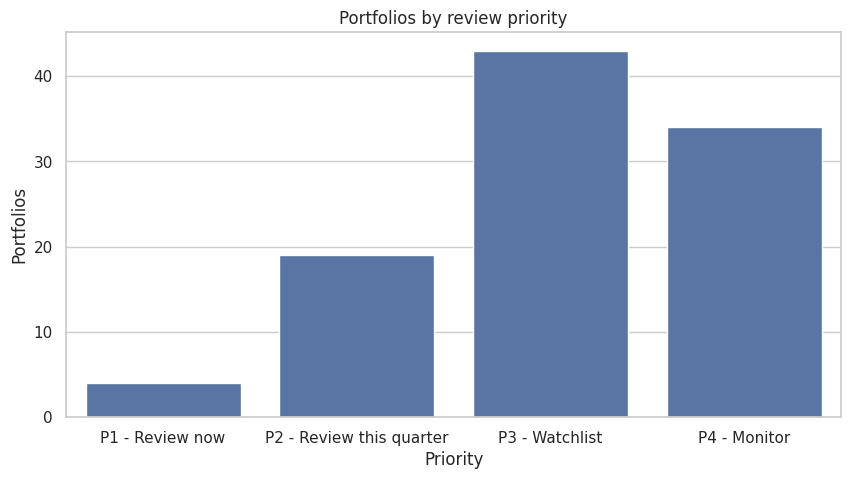

4 portfolios need review now and 19 more this quarter. Indicative trades for P1 and P2: INR 1.18 crore.
Client question: 14 of 100 portfolios are Conservative with a 75% equity limit or Aggressive with a 35% limit. Confirm which is wrong, the profile or the limit.
Action: take P1 to the Committee first. Where the breach comes from a limit that does not match the profile, fix the mandate before trading.


In [ ]:
print(pd.crosstab(q10['RiskProfile'], q10['Priority']).loc[order])
print()
trade_by_priority = q10.groupby(['RiskProfile', 'Priority'])['IndicativeTradeINR'].sum().unstack(fill_value=0).loc[order] / 1e7
print('Indicative trades, INR crore:')
print(trade_by_priority.round(2))

plt.figure(figsize=(10, 5))
sns.countplot(data=q10, x='Priority', order=sorted(q10['Priority'].unique()))
plt.title('Portfolios by review priority')
plt.ylabel('Portfolios')
plt.show()

n_p1 = (q10['Priority'] == 'P1 - Review now').sum()
n_p2 = (q10['Priority'] == 'P2 - Review this quarter').sum()
trade = q10[q10['Priority'].isin(['P1 - Review now', 'P2 - Review this quarter'])]['IndicativeTradeINR'].sum() / 1e7
print(n_p1, 'portfolios need review now and', n_p2, 'more this quarter. Indicative trades for P1 and P2: INR', round(trade, 2), 'crore.')
bad = q10[((q10['RiskProfile'] == 'Conservative') & (q10['EquityLimitPct'] == 75)) | ((q10['RiskProfile'] == 'Aggressive') & (q10['EquityLimitPct'] == 35))]
print('Client question:', len(bad), 'of', len(q10), 'portfolios are Conservative with a 75% equity limit or Aggressive with a 35% limit. Confirm which is wrong, the profile or the limit.')
print('Action: take P1 to the Committee first. Where the breach comes from a limit that does not match the profile, fix the mandate before trading.')

## 12. Export (Studio 6 and Integrated Pipeline studios)
- **Excel workbook** with separate sheets: Cleaned Data, KPI Summary, Data Quality Checks, then the analysis sheets. The summary sheet has one row per risk profile and reconciles to the portfolio-level drill-down (Q10 sheet).
- **CSV files** for loading back into SQL Server.
- **GenAI-safe table:** aggregated only, no portfolio IDs. Verify the numbers before using them in a prompt.

In [ ]:
# Summary dataset: one row per risk profile (grain), reconciled to the drill-down
q10['IsPersistent'] = (q10['AllocationStatus'] == 'Persistent').astype(int)
q10['IsP1orP2'] = q10['Priority'].isin(['P1 - Review now', 'P2 - Review this quarter']).astype(int)

summary_profile = q10.groupby('RiskProfile', as_index=False).agg(
    Portfolios=('PortfolioID', 'count'),
    AvgRiskScore=('RiskScore', 'mean'),
    InEquityBreachNow=('EquityBreach', 'sum'),
    PersistentBreach=('IsPersistent', 'sum'),
    ReviewNowOrQuarter=('IsP1orP2', 'sum'),
    IndicativeTradeINR=('IndicativeTradeINR', 'sum'))
print('Summary reconciles to drill-down:', summary_profile['Portfolios'].sum() == len(q10), '|', round(summary_profile['IndicativeTradeINR'].sum()) == round(q10['IndicativeTradeINR'].sum()))

# GenAI-safe aggregate: by profile and equity limit, no portfolio IDs
genai = q10.groupby(['RiskProfile', 'EquityLimitPct'], as_index=False).agg(
    Portfolios=('PortfolioID', 'count'),
    AvgRiskScore=('RiskScore', 'mean'),
    InEquityBreachNow=('EquityBreach', 'sum'),
    PersistentBreach=('IsPersistent', 'sum'),
    ReviewNowOrQuarter=('IsP1orP2', 'sum'),
    IndicativeTradeINRcrore=('IndicativeTradeINR', 'sum'))
genai['IndicativeTradeINRcrore'] = genai['IndicativeTradeINRcrore'] / 1e7
summary_profile

Summary reconciles to drill-down: True | True


,RiskProfile,Portfolios,AvgRiskScore,InEquityBreachNow,PersistentBreach,ReviewNowOrQuarter,IndicativeTradeINR
0,Aggressive,27,30.04,4,6,5,"5,747,026.95"
1,Conservative,37,34.30,15,10,12,"11,189,285.00"
2,Moderate,36,27.84,7,6,6,"9,992,098.95"


In [ ]:
# CSV files for SQL
pm_out = pm.copy()
pm_out['Month'] = pm_out['Month'].dt.strftime('%Y-%m-%d')
pm_out.to_csv(OUT_DIR + 'py_portfolio_month.csv', index=False)
final[['PortfolioID', 'RiskProfile', 'RiskScore', 'Band', 'Persistence', 'EquityExcess', 'Concentration', 'Volatility', 'Drawdown', 'Currency']].to_csv(OUT_DIR + 'py_portfolio_risk_score.csv', index=False)
q10.drop(columns=['IsPersistent', 'IsP1orP2']).to_csv(OUT_DIR + 'py_rebalancing_priority.csv', index=False)
q6.to_csv(OUT_DIR + 'py_persistence.csv', index=False)
scen[['PortfolioID', 'RiskProfile', 'MarketValueINR'] + pct_cols].to_csv(OUT_DIR + 'py_scenarios.csv', index=False)
genai.to_csv(OUT_DIR + 'genai_verified_aggregates.csv', index=False)

# Excel workbook with one sheet per output
with pd.ExcelWriter(OUT_DIR + 'P07_Python_Report.xlsx') as writer:
    pm_out.to_excel(writer, sheet_name='Cleaned Data', index=False)
    kpi.to_excel(writer, sheet_name='KPI Summary', index=False)
    quality.to_excel(writer, sheet_name='Data Quality Checks', index=False)
    control.to_excel(writer, sheet_name='Control Totals', index=False)
    summary_profile.to_excel(writer, sheet_name='Summary by Profile', index=False)
    outlier_review.to_excel(writer, sheet_name='Outlier Review', index=False)
    q3.to_excel(writer, sheet_name='Q3 Return vs Risk', index=False)
    q6.to_excel(writer, sheet_name='Q6 Persistence', index=False)
    scenario_summary.to_excel(writer, sheet_name='Q8 Scenario Summary', index=False)
    scen[['PortfolioID', 'RiskProfile', 'MarketValueINR'] + pct_cols].to_excel(writer, sheet_name='Q8 By Portfolio', index=False)
    forecast_error.to_excel(writer, sheet_name='Forecast Error', index=False)
    stability.to_excel(writer, sheet_name='Forecast Stability', index=False)
    backtest.to_excel(writer, sheet_name='Q9 Score Backtest', index=False)
    final.to_excel(writer, sheet_name='Q9 Risk Scores', index=False)
    q10.drop(columns=['IsPersistent', 'IsP1orP2']).to_excel(writer, sheet_name='Q10 Priority List', index=False)

print('Excel sheets:', pd.ExcelFile(OUT_DIR + 'P07_Python_Report.xlsx').sheet_names)
print('Files saved:', sorted(os.listdir(OUT_DIR)))

Excel sheets: ['Cleaned Data', 'KPI Summary', 'Data Quality Checks', 'Control Totals', 'Summary by Profile', 'Outlier Review', 'Q3 Return vs Risk', 'Q6 Persistence', 'Q8 Scenario Summary', 'Q8 By Portfolio', 'Forecast Error', 'Forecast Stability', 'Q9 Score Backtest', 'Q9 Risk Scores', 'Q10 Priority List']
Files saved: ['P07_Python_Report.xlsx', 'genai_verified_aggregates.csv', 'py_persistence.csv', 'py_portfolio_month.csv', 'py_portfolio_risk_score.csv', 'py_rebalancing_priority.csv', 'py_scenarios.csv']
